# Etapa 5: Random Forest

Entrada: a mesma matriz de features e os mesmos splits do notebook 03 (`modeling.prepare`).

Uma **Random Forest** treina muitas Random Trees (notebook 04), cada uma numa amostra bootstrap do treino: um sorteio com reposição do mesmo tamanho do treino. Para classificar, ela faz a média das probabilidades de todas as árvores. Duas fontes de aleatoriedade, portanto: o sorteio de linhas (bootstrap) e o sorteio de atributos em cada nó.

No notebook 03 a Random Forest entrava só como teto, com os hiperparâmetros padrão. Aqui ela é ajustada e avaliada com as mesmas análises da árvore, sempre no cenário escolhido: descritores + SMILES, split agrupado.

O código fica em `src/random_forest.py`; a busca e a avaliação são as de `src/modeling.py`.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import modeling, plots, random_forest as rf
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)
print("X:", dados.X.shape, "| classes:", dados.y.nunique())

X: (27476, 17) | classes: 4


## 1. Busca de hiperparâmetros

Grid pequeno, com 300 árvores fixas e a mesma validação cruzada agrupada da árvore de decisão (6 combinações × 5 partes = 30 florestas):

- `max_features`: 0,15, `sqrt` e 0,5 do total de atributos, ou seja K = 2, 4 e 8 com 17 atributos;
- `min_samples_leaf`: 1, 3.

Uma primeira rodada também testou `max_depth=20`, que nunca superou a árvore sem limite e saiu do grid.

O erro out-of-bag (OOB), que a floresta calcula sem custo extra, não é usado: as linhas fora da amostra de uma árvore ignoram os grupos de descritores repetidos, e uma molécula seria avaliada por uma árvore que viu a gêmea dela.

In [2]:
busca, floresta = modeling.tune_chosen(dados, rf.estimator(dados.seed), rf.PARAM_GRID)
busca

,max_features,min_samples_leaf,acurácia CV,desvio CV,segundos por ajuste
0,0.15,1,0.945,0.002,5.6
1,sqrt,1,0.944,0.003,8.0
2,0.5,1,0.941,0.002,12.9
3,sqrt,3,0.931,0.003,9.8
4,0.5,3,0.930,0.002,13.6
5,0.15,3,0.928,0.003,7.1


In [3]:
params = modeling.chosen_params(floresta, rf.PARAM_GRID)
print("parâmetros escolhidos:", params)
pd.DataFrame({"padrão (notebook 03)": modeling.reference_models(dados, only=["Random Forest (300 árvores)"]).iloc[0],
              "ajustada": pd.Series(modeling.test_scores(floresta, dados))})

parâmetros escolhidos: {'max_features': 0.15, 'min_samples_leaf': 1}


,padrão (notebook 03),ajustada
acurácia teste,0.952,0.949
F1 macro teste,0.952,0.949


As três primeiras combinações ficam dentro de 0,4 ponto de validação: 0,945, 0,944 e 0,941, com desvio entre as partes de 0,2 a 0,3 ponto. A única escolha que pesa é a folha mínima: subir de 1 para 3 linhas custa cerca de 1,4 ponto em qualquer K. Como na árvore de decisão, aqui também vale deixar as árvores crescerem até o fim.

A busca escolhe K = 2 (`max_features = 0,15`), mas no teste a floresta ajustada (0,949) não supera a padrão (0,952, com K = 4). A diferença está dentro do ruído: os padrões do scikit-learn já servem bem para esta base. O notebook 07 confirma isso com 10 seeds.

## 2. Quantas árvores

A floresta escolhida é treinada uma vez com 300 árvores num fold de validação agrupado tirado do treino. A curva mede a acurácia usando só as primeiras n árvores: como a floresta é uma média, basta acumular as probabilidades árvore a árvore. O teste não é usado.

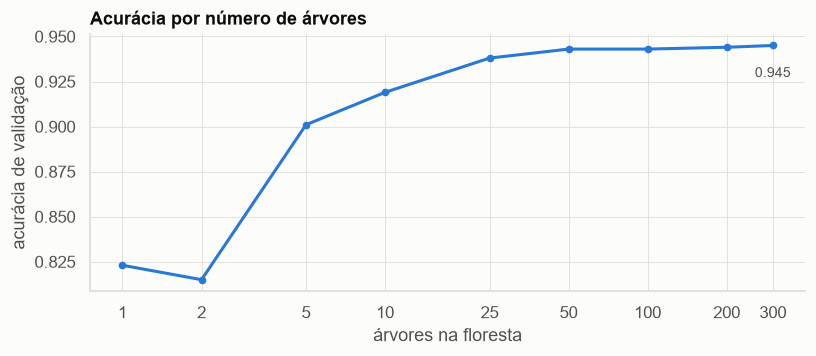

árvores,1,2,5,10,25,50,100,200,300
validação,0.823,0.815,0.901,0.919,0.938,0.943,0.943,0.944,0.945


In [4]:
curva = rf.n_trees_curve(dados, params)
plots.n_trees_curve(curva)
curva.T

Uma árvore só acerta 0,823 na validação, bem abaixo da árvore de decisão (0,878 na validação cruzada do notebook 03). Isso é esperado: ela sorteia apenas 2 atributos por nó e vê só uma amostra bootstrap, que deixa de fora cerca de um terço das linhas do treino. Com 2 árvores a acurácia ainda cai (0,815), porque um empate entre duas árvores que discordam vira quase um sorteio.

Daí em diante, cada árvore nova ajuda: 0,901 com 5, 0,938 com 25 e 0,943 com 50. Depois de 50 árvores a curva fica plana (0,945 com 300). As 300 árvores do padrão sobram, mas não atrapalham: na floresta, árvores a mais não causam overfitting, só custam tempo.

## 3. Avaliação no conjunto de teste

In [5]:
relatorio, matriz = modeling.evaluation(floresta, dados)
relatorio

,precisão,revocação,F1,linhas
EGFR,0.938,0.955,0.946,1612.000
BACE1,0.968,0.941,0.954,1463.000
DRD2,0.952,0.964,0.958,1307.000
HDAC1,0.939,0.934,0.937,1114.000
accuracy,0.949,0.949,0.949,0.949
macro avg,0.949,0.949,0.949,5496.000


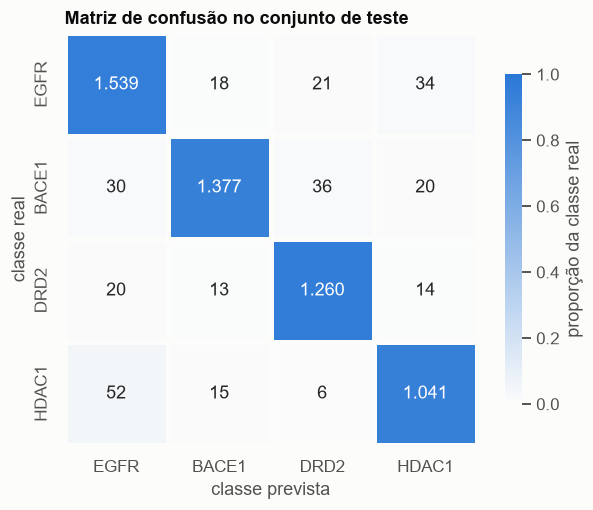

In [6]:
plots.confusion_matrix(matriz)

Acurácia de 0,949 e F1 macro de 0,949: 5,2 pontos acima da árvore de decisão (0,897) no mesmo teste. Todas as classes melhoram. HDAC1 continua a mais difícil (F1 0,937, contra 0,868 da árvore), e DRD2 a mais fácil (0,958).

## 4. Importância das features

As mesmas duas medidas do notebook 03. Na floresta, a importância por impureza é a média sobre as 300 árvores.

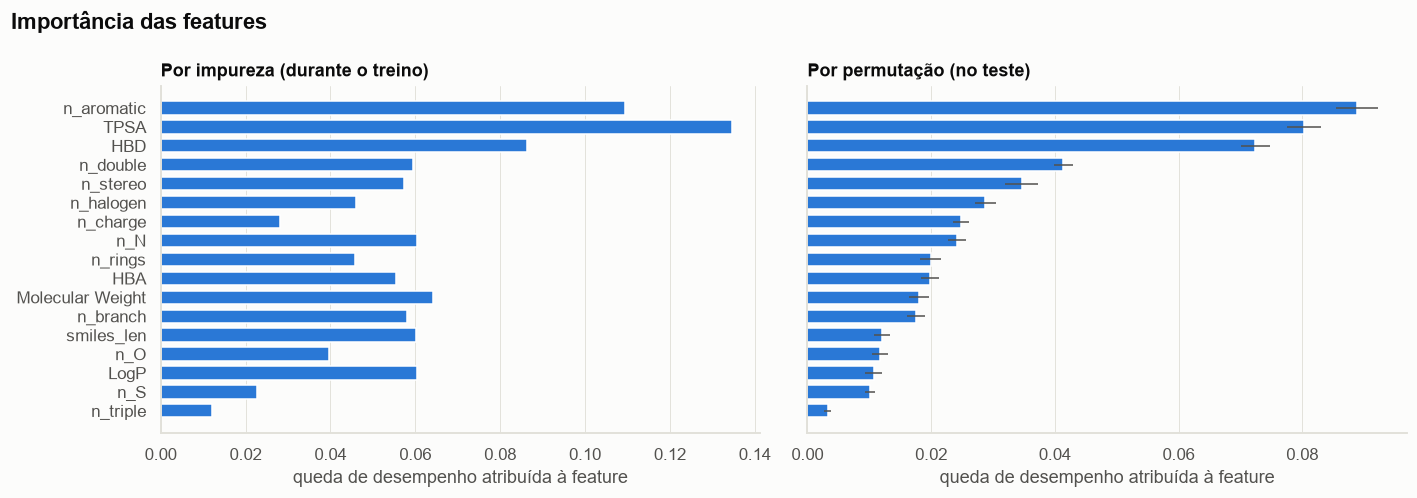

In [7]:
plots.feature_importances(modeling.importances(floresta, dados))

O topo é o mesmo da árvore: `n_aromatic`, TPSA e HBD, agora com `n_aromatic` em primeiro na permutação. Duas diferenças aparecem.

- **A permutação dá valores bem menores.** Embaralhar TPSA derruba a floresta em 8 pontos; na Random Tree (notebook 04), em 26 pontos. Como cada árvore da floresta só vê parte dos atributos em cada nó, muitas aprenderam a separar as classes sem TPSA, usando atributos correlacionados. Quando um atributo some, as outras árvores compensam.
- **A impureza espalha o crédito.** LogP, peso molecular e `smiles_len` recebem cerca de 0,06 de impureza cada, dois terços do que HBD recebe, mas ficam no fim da lista na permutação. A importância por impureza favorece atributos contínuos, com muitos cortes possíveis, mesmo quando eles pouco ajudam no teste.

## 5. A floresta sabe quando está em dúvida?

A árvore de decisão do notebook 03 dava 100% de confiança em todas as previsões, porque toda folha era pura. Na floresta, a probabilidade é a fração de árvores que votam em cada classe, então ela pode expressar dúvida.

In [8]:
modeling.confidence_table(floresta, dados, top_label="100% (todas as árvores concordam)")

,previsões,% do teste,acurácia
faixa,,,
até 50%,331,6.0,0.529
50-70%,759,13.8,0.870
70-90%,1734,31.6,0.986
90-100%,2390,43.5,1.000
100% (todas as árvores concordam),282,5.1,1.000


**A floresta sabe quando está em dúvida, e a árvore de decisão não.** Só 5,1% das previsões são unânimes. Quando a confiança passa de 90%, a floresta acerta 100% das vezes; entre 70% e 90%, acerta 98,6%. Os erros se concentram nas previsões de baixa confiança: as 1.090 previsões abaixo de 70% de confiança (19,8% do teste) carregam cerca de 255 dos 280 erros, 91% deles.

Isso torna a confiança útil na prática. Um químico poderia revisar à mão só as moléculas com confiança abaixo de 70% e encontrar ali quase todos os erros. Com a árvore de decisão, que diz 100% em tudo, isso é impossível.

## 6. Análise de erro

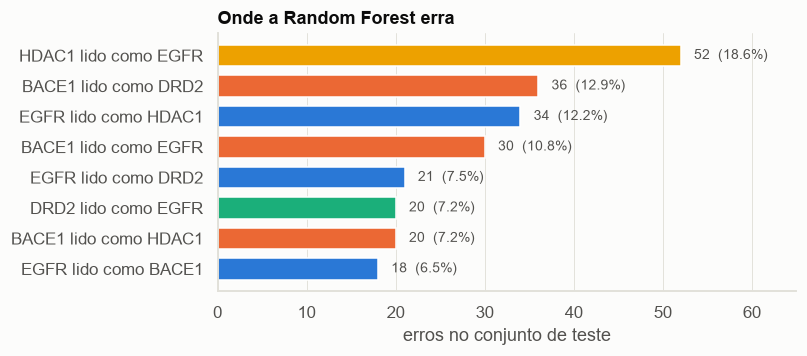

,real,prevista,erros,% dos erros,% da classe real
0,HDAC1,EGFR,52,18.6,4.7
1,BACE1,DRD2,36,12.9,2.5
2,EGFR,HDAC1,34,12.2,2.1
3,BACE1,EGFR,30,10.8,2.1
4,EGFR,DRD2,21,7.5,1.3
5,DRD2,EGFR,20,7.2,1.5


In [9]:
erros = modeling.error_overview(floresta, dados)
plots.error_pairs(erros, title="Onde a Random Forest erra")
erros.head(6)

A floresta erra 280 moléculas, contra cerca de 570 da árvore de decisão: menos da metade. O par HDAC1 ↔ EGFR continua no topo, com 30,8% dos erros nos dois sentidos. Os conjuntos de árvores reduzem os erros, mas não resolvem a confusão de fundo entre essas duas classes. Ela vem da representação, que conta átomos e não enxerga grupos como o ácido hidroxâmico dos inibidores de HDAC (notebook 03).

## 7. Resumo

| Cenário (descritores + SMILES, split agrupado) | Acurácia no teste |
|---|---|
| Árvore de decisão (notebook 03) | 0,897 |
| Random Forest padrão (300 árvores, K = 4) | 0,952 |
| Random Forest ajustada (300 árvores, K = 2) | 0,949 |

- **A floresta ganha cerca de 5 pontos sobre a árvore.** Todas as classes melhoram, e os erros caem para menos da metade.
- **O ajuste não muda nada.** As melhores combinações ficam dentro do ruído da validação, e no teste a floresta padrão empata com a ajustada. Só a folha mínima importa: tem que ser 1.
- **50 árvores bastam.** A curva fica plana a partir daí; as 300 árvores do padrão só custam tempo.
- **A confiança é útil.** Acima de 70% de confiança a floresta quase não erra; 91% dos erros estão nas previsões abaixo de 70%.
- **O preço é a legibilidade.** Não existe um caminho de perguntas que explique uma previsão: são 300 árvores votando. As importâncias dizem quais atributos pesam no conjunto, não por que uma molécula específica foi classificada como DRD2.